# 02 · Hotel KPIs: cancellations, prices and seasonality

**Question:** how often are bookings cancelled, at what price are rooms sold, how do both change through the year, and how much revenue do cancellations put at risk? The resort and the city hotel are compared throughout.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/hotel_bookings_clean.csv", parse_dates=["arrival_date"])

MONTHS = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]
COLORS = {"City Hotel": "#2a78d6", "Resort Hotel": "#eb6834"}

print(df.shape)

(119208, 36)


## 2.1 Headline KPIs by hotel

**ADR (Average Daily Rate)** is computed as hotels do: room revenue ÷ room-nights sold, using only stays that took place (not cancelled), with `adr` > 0 and at least one night. **Revenue lost** is the revenue of cancelled bookings: an upper bound, since some rooms are resold and some deposits are kept.

In [2]:
kpi = df.groupby("hotel").agg(
    n_bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
)
kpi["cancel_rate"] = (kpi["cancel_rate"] * 100).round(1)

stays = df[(df["is_canceled"] == 0) & (df["adr"] > 0) & (df["total_nights"] > 0)]
kpi["adr"] = (stays.groupby("hotel")["revenue"].sum()
              / stays.groupby("hotel")["total_nights"].sum()).round(1)
kpi["revenue_lost"] = df[df["is_canceled"] == 1].groupby("hotel")["revenue"].sum().round(0)
kpi

,n_bookings,cancel_rate,adr,revenue_lost
hotel,,,,
City Hotel,79162,41.8,108.0,10879660.0
Resort Hotel,40046,27.8,97.6,5842177.0


- The City Hotel has 66% of bookings and a cancellation rate of **41.8%**, 1.5x the Resort's **27.8%**.
- ADR is 108.0 for the City Hotel and 97.6 for the Resort (yearly average; see the seasonality below).
- Cancelled bookings represent **~16.7M** of potential revenue over 26 months (10.9M City, 5.8M Resort). The currency is not stated in the source (likely EUR).

## 2.2 Cancellation rate by month

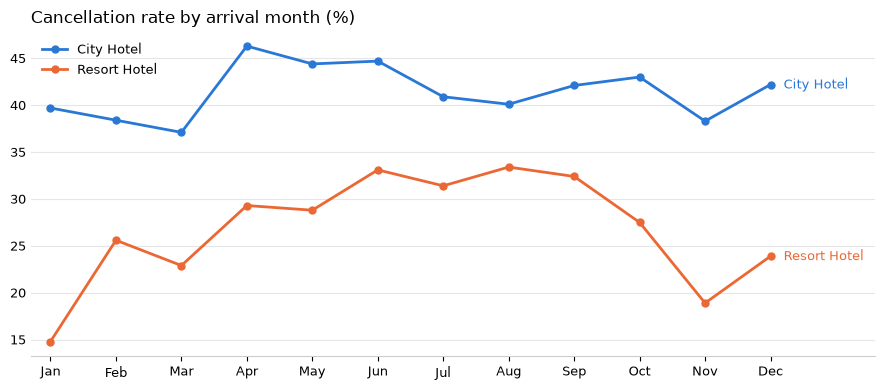

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,39.7,14.8
February,38.4,25.6
March,37.1,22.9
April,46.3,29.3
May,44.4,28.8
June,44.7,33.1
July,40.9,31.4
August,40.1,33.4
September,42.1,32.4


In [3]:
cancel_month = (
    df.groupby(["arrival_date_month", "hotel"])["is_canceled"]
      .mean().mul(100).round(1)
      .rename("cancel_rate").reset_index()
)

def plot_by_month(data, value, title, fname):
    fig, ax = plt.subplots(figsize=(9, 4))
    for hotel, color in COLORS.items():
        s = data[data["hotel"] == hotel].set_index("arrival_date_month")[value].reindex(MONTHS)
        ax.plot(range(12), s.values, color=color, linewidth=2, marker="o", markersize=5, label=hotel)
        ax.text(11.2, s.values[-1], hotel, color=color, va="center", fontsize=9)
    ax.set_xticks(range(12))
    ax.set_xticklabels([m[:3] for m in MONTHS], fontsize=9)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#ccc")
    ax.tick_params(axis="y", length=0, labelsize=9)
    ax.set_xlim(-0.3, 12.6)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.set_title(title, loc="left", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

plot_by_month(cancel_month, "cancel_rate", "Cancellation rate by arrival month (%)", "cancel_rate_by_month.png")
cancel_month.pivot(index="arrival_date_month", columns="hotel", values="cancel_rate").reindex(MONTHS)

- **City Hotel:** cancellations are high all year (37–46%), peaking in April–June.
- **Resort Hotel:** cancellations are seasonal, from **14.8% in January** to **33–34% in June–August**.
- The gap between the two hotels is largest in winter (~25 points in January) and smallest in summer (~7 points in August).

## 2.3 ADR by month

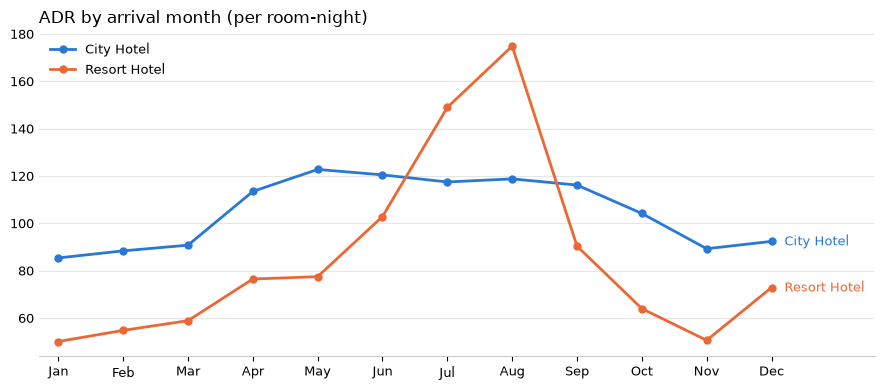

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,85.4,50.1
February,88.4,54.8
March,90.8,58.9
April,113.5,76.5
May,122.8,77.5
June,120.5,102.9
July,117.5,149.0
August,118.8,174.9
September,116.2,90.4


In [4]:
g = stays.groupby(["arrival_date_month", "hotel"])
adr_month = (g["revenue"].sum() / g["total_nights"].sum()).round(1).rename("adr").reset_index()

plot_by_month(adr_month, "adr", "ADR by arrival month (per room-night)", "adr_by_month.png")
adr_month.pivot(index="arrival_date_month", columns="hotel", values="adr").reindex(MONTHS)

- Resort prices are highly seasonal: ADR from **50.1 in January to 174.9 in August (3.5x)**. The Resort is more expensive than the City Hotel only in July and August.
- The City Hotel ranges from 85.4 to 122.8 (1.4x) and peaks in May–June, a typical city and business travel pattern.
- In both hotels **cancellations are highest when prices are highest**: revenue at risk is concentrated in peak season.

## 2.4 Lead time

In [5]:
bins = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
labels = ["1. 0-7 days", "2. 8-30 days", "3. 1-3 months",
          "4. 3-6 months", "5. 6-12 months", "6. Over 1 year"]
df["lead_bucket"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

lead = df.groupby("lead_bucket", observed=True).agg(
    n_bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
)
lead["cancel_rate"] = (lead["cancel_rate"] * 100).round(1)
lead

,n_bookings,cancel_rate
lead_bucket,,
1. 0-7 days,19635,9.6
2. 8-30 days,18945,27.9
3. 1-3 months,29528,37.7
4. 3-6 months,26420,44.7
5. 6-12 months,21533,55.5
6. Over 1 year,3147,67.7


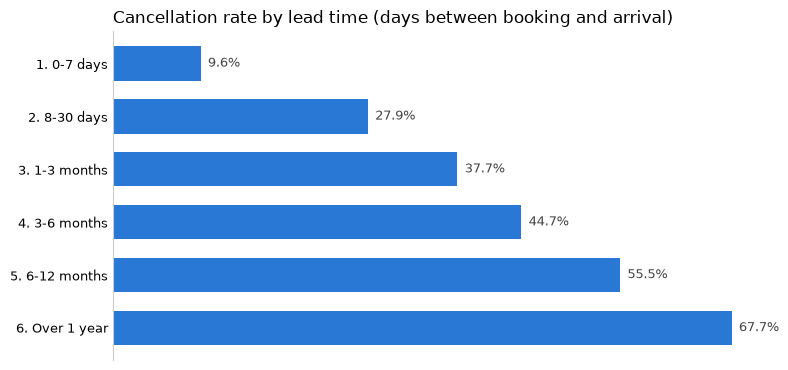

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = lead.index.astype(str)[::-1]
v = lead["cancel_rate"].values[::-1]
ax.barh(y, v, color="#2a78d6", height=0.65)
for i, val in enumerate(v):
    ax.text(val + 0.8, i, f"{val:.1f}%", va="center", fontsize=9, color="#444")
ax.xaxis.set_visible(False)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.tick_params(axis="y", labelsize=9, length=0)
ax.set_title("Cancellation rate by lead time (days between booking and arrival)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/cancel_by_lead_time.png", dpi=150, bbox_inches="tight")
plt.show()

Lead time is the strongest single signal: the cancellation rate rises at every step, from **9.6%** for bookings made within a week of arrival to **55.5%** at 6–12 months and **67.7%** over one year (7x). It also explains the Resort's summer peak, since summer holidays are booked months ahead.

## 2.5 Deposit type

In [7]:
dep = df.groupby("deposit_type").agg(
    n_bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
)
dep["cancel_rate"] = (dep["cancel_rate"] * 100).round(1)
dep

,n_bookings,cancel_rate
deposit_type,,
No Deposit,104460,28.4
Non Refund,14586,99.4
Refundable,162,22.2


Counterintuitive: **"Non Refund" bookings are cancelled 99.4% of the time**, vs 28.4% with no deposit. A guest who paid a non-refundable deposit should cancel less, not more. Who makes these bookings?

In [8]:
nr = df[df["deposit_type"] == "Non Refund"]
print(nr["hotel"].value_counts(normalize=True).round(3), "\n")
print(nr["market_segment"].value_counts(normalize=True).round(3), "\n")
print(f"Share of duplicated rows: {nr['is_duplicate'].mean():.1%}")
print(f"Average lead time: {nr['lead_time'].mean():.0f} days vs {df['lead_time'].mean():.0f} overall")

hotel
City Hotel      0.882
Resort Hotel    0.118
Name: proportion, dtype: float64 

market_segment
Groups           0.629
Offline TA/TO    0.343
Corporate        0.023
Online TA        0.004
Direct           0.001
Name: proportion, dtype: float64 

Share of duplicated rows: 98.1%
Average lead time: 213 days vs 104 overall


In [9]:
no_nr = df[df["deposit_type"] != "Non Refund"]
(no_nr.groupby("hotel")["is_canceled"].mean() * 100).round(1)

hotel
City Hotel      30.5
Resort Hotel    24.7
Name: is_canceled, dtype: float64

- Non Refund bookings (14,586) are almost all **group and tour-operator room blocks**: 97% Groups or Offline TA/TO, 98.1% duplicated rows, 88% City Hotel, booked ~213 days ahead (vs 104 overall).
- The label most likely reflects the contract terms of the block, or a coding issue in the source data, rather than an individual non-refundable payment. If deposits were kept, these cancellations overstate revenue lost.
- Excluding them, the cancellation rate drops from 41.8% to **30.5%** for the City Hotel and from 27.8% to **24.7%** for the Resort: the gap between the hotels shrinks from 14 to 6 points. For the City Hotel, group contracts are the first lever.

## 2.6 Other signals

In [10]:
for col in ["market_segment", "is_repeated_guest", "total_of_special_requests"]:
    t = df.groupby(col).agg(
        n_bookings=("is_canceled", "size"),
        cancel_rate=("is_canceled", "mean"),
    )
    t["cancel_rate"] = (t["cancel_rate"] * 100).round(1)
    display(t.sort_values("cancel_rate", ascending=False))

,n_bookings,cancel_rate
market_segment,,
Undefined,2,100.0
Groups,19790,61.1
Online TA,56408,36.8
Offline TA/TO,24181,34.3
Aviation,235,22.1
Corporate,5282,18.8
Direct,12582,15.4
Complementary,728,12.2


,n_bookings,cancel_rate
is_repeated_guest,,
0,115454,37.8
1,3754,14.7


,n_bookings,cancel_rate
total_of_special_requests,,
0,70199,47.8
2,12952,22.1
1,33183,22.0
3,2494,17.8
4,340,10.6
5,40,5.0


- **Market segment:** Groups cancel most (61.1%); online travel agencies, the largest segment (47% of bookings), cancel 36.8%; **direct bookings only 15.4%** (2.4x less).
- **Repeat guests** cancel 14.7% vs 37.8% for new guests (2.6x less), but they are only 3.1% of bookings.
- **Special requests:** guests with no request cancel 47.8%; with at least one request ~22% or less. A request (cot, high floor, extra bed) signals a guest who is already planning the stay.

## Findings

1. **The City Hotel has the bigger cancellation problem, but a quarter of it comes from group blocks.** Cancellation rate 41.8% vs 27.8% for the Resort; excluding Non Refund group blocks (cancelled 99.4% of the time) the rates are 30.5% and 24.7%.
2. **Cancellations are highest when rooms are most expensive.** Resort ADR rises from 50.1 in January to 174.9 in August (3.5x), and its cancellations from 14.8% to 33–34%. The City Hotel peaks in spring for both.
3. **Lead time is the strongest single signal:** from 9.6% (booked within a week) to 67.7% (booked over a year ahead).
4. **Commitment signals go with fewer cancellations:** direct bookings (15.4% vs 36.8% for online agencies), repeat guests (14.7% vs 37.8%) and guests with special requests (~22% vs 47.8%).

**Revenue at stake:** ~16.7M of potential revenue over 26 months, an upper bound (resold rooms, kept deposits).

**Caveats:** correlations, not causes; only 2016 is a full year; currency not stated (likely EUR).